# Efficient inference under label shift

Lee, Ma & Zhao, JMLR 27 (2026), *Efficient Inference under Label Shift in
Unsupervised Domain Adaptation*. This independent implementation follows
Algorithms 1-2 for the target mean and Section 5 for discrete labels.

The workflow mirrors `ppi.ipynb`: data -> target -> estimator -> result.
Run from `examples/simulation/`. The extra case explicitly changes label
prevalence while keeping **P(X|Y)=Q(X|Y)**. It evaluates the target population
mean, never the source mean or the realized target sample mean.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from openppi import EfficientLabelShift, LabelShiftData, Mean, get_method
from dataset.label_shift_sim import make_label_shift_case, make_continuous_label_shift_case
from label_shift import run_simulation


## 1. Source/target data with label shift

Source labels have prevalence 0.3, target labels prevalence 0.7. In both domains,
`X|Y ~ Normal(2Y-1, 1)`. The score is the fixed source Bayes posterior `P_P(Y=1|X)`
from the specified DGP. Knowing this source predictor isolates the effects of
label shift; it does not reveal target labels or the target label ratio.
The generator returns no target outcomes to either estimator.

`LabelShiftData` accepts covariates and optionally a full source conditional
class probability vector. Scalar conditional mean predictions alone are not
sufficient for the paper's general algorithm. Here the two-column probabilities
are `[P_P(Y=0|X), P_P(Y=1|X)]` on source rows, then target rows.


In [2]:
data, standard_ppi_data, truth = make_label_shift_case(seed=0)
target = Mean()
print('Target population truth:', truth)
print('Observed source label mean:', data.labels.mean())
print('Source feature shape:', data.labeled_features.shape)
print('Target feature shape:', data.unlabeled_features.shape)
print('Conditional probability shape:', data.conditional_probabilities.shape)


Target population truth: 0.7
Observed source label mean: 0.37333333333333335
Source feature shape: (300, 1)
Target feature shape: (1500, 1)
Conditional probability shape: (1800, 2)


## 2. The same inference interface as PPI

The source residual correction is weighted by an estimated label-density ratio.
The auxiliary predictions are constructed by the conditional operator equation,
rather than reusing the raw source mean predictions without adjustment.
`refine_ratio=True` additionally implements Section 3.2's density-ratio update.


In [3]:
rows = []
for name in ('PPI', 'PPI++', 'LabelShift'):
    record = data if name == 'LabelShift' else standard_ppi_data
    result = get_method(name).inference(record, target=target)
    lo, hi = result.confidence_interval
    rows.append(dict(method=name, estimate=result.estimate, se=result.standard_error,
                     lower=lo, upper=hi, covered=lo <= truth <= hi))
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f'{v:.4f}'))

result = EfficientLabelShift(refine_ratio=True)(data, target=target)
print('Estimated label ratios [0, 1]:', result.diagnostics['density_ratio'])
print('Estimated target class probabilities:', result.diagnostics['estimated_target_probabilities'])
print('Functional equation residual:', result.diagnostics['fredholm_residual'])
print('Source and target variance terms:', result.diagnostics['source_variance'], result.diagnostics['target_variance'])


    method  estimate     se  lower  upper  covered
       PPI    0.5518 0.0211 0.5104 0.5931    False
     PPI++    0.5102 0.0211 0.4689 0.5515    False
LabelShift    0.7028 0.0274 0.6492 0.7565     True
Estimated label ratios [0, 1]: [0.47418483 1.88261833]
Estimated target class probabilities: [0.29715582 0.70284418]
Functional equation residual: 2.220446049250313e-16
Source and target variance terms: 0.0005232668221375073 0.0002604869187108683


## 3. Extra simulation case, with a no-shift control

300 repetitions per case, source n=300 and target m=1500. The control has target
prevalence 0.3; the shifted case has target prevalence 0.7. Both use the same
source distribution and class-conditional feature model. All methods use the
same source predictor. `Source-only` is the ordinary mean of source labels;
it is included to show why target and source means must be distinguished.

We report bias, RMSE, average interval length, and coverage. Failed runs remain
in the experiment output. `coverage` uses successful runs; `coverage_all`
counts failures as uncovered. This is an illustrative benchmark, not the
paper's full experimental reproduction. With 300 repetitions, Monte Carlo
uncertainty in a coverage estimate near 95% is about 1.3 percentage points.


In [4]:
per_rep, summary = run_simulation(reps=300, n=300, m=1500, seed=20261102)
columns = ['case', 'method', 'bias', 'rmse', 'coverage', 'coverage_mc_se',
           'average_length', 'failure_rate']
print(summary[columns].to_string(index=False, float_format=lambda v: f'{v:.4f}'))
# To save the full results and configuration, run:
# python label_shift.py --reps 300 --out results_label_shift


       case             method    bias   rmse  coverage  coverage_mc_se  average_length  failure_rate
   no_shift        Source-only  0.0006 0.0249    0.9633          0.0109          0.1038        0.0000
   no_shift                PPI  0.0002 0.0191    0.9567          0.0118          0.0783        0.0000
   no_shift              PPI++ -0.0004 0.0188    0.9533          0.0122          0.0772        0.0000
   no_shift         LabelShift  0.0005 0.0282    0.9500          0.0126          0.1163        0.0000
   no_shift LabelShift-refined  0.0005 0.0285    0.9500          0.0126          0.1163        0.0000
label_shift        Source-only -0.3994 0.4002    0.0000          0.0000          0.1038        0.0000
label_shift                PPI -0.1886 0.1896    0.0000          0.0000          0.0796        0.0000
label_shift              PPI++ -0.2519 0.2532    0.0000          0.0000          0.0787        0.0000
label_shift         LabelShift -0.0039 0.0319    0.9267          0.0151          0

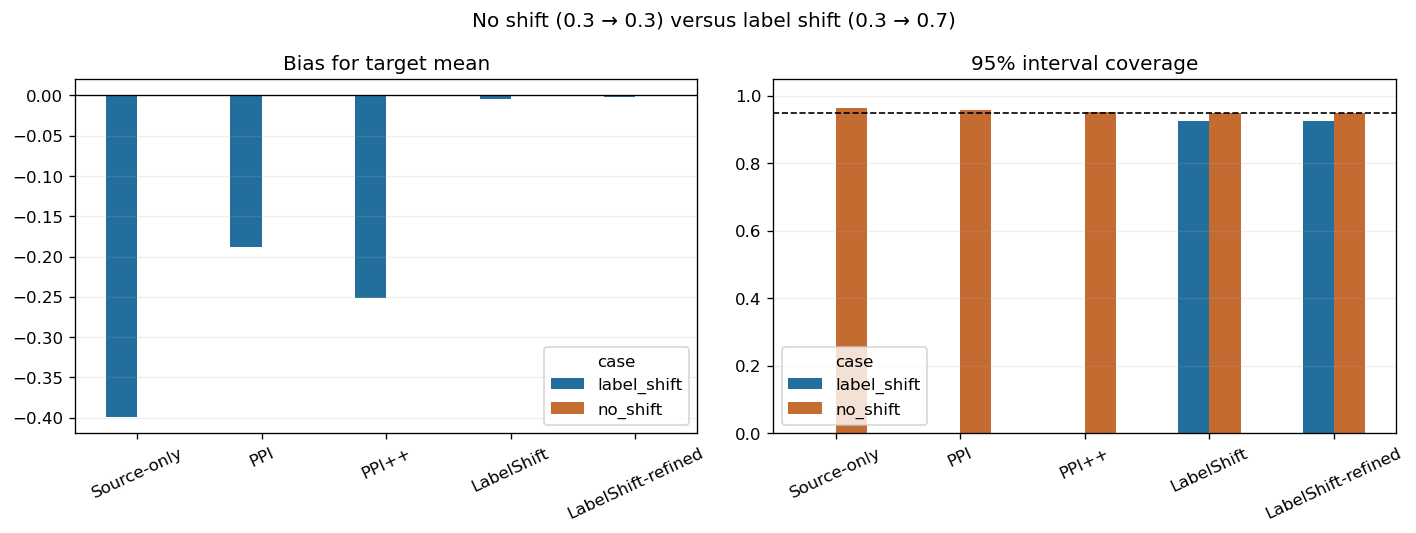

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ['bias', 'coverage'], ['Bias for target mean', '95% interval coverage']):
    values = summary.pivot(index='method', columns='case', values=metric)
    values = values.reindex(['Source-only', 'PPI', 'PPI++', 'LabelShift', 'LabelShift-refined'])
    values.plot.bar(ax=ax, color=['#226e9c', '#c46b32'], rot=25)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=.2)
axes[0].axhline(0, color='black', linewidth=.8)
axes[1].axhline(.95, color='black', linestyle='--', linewidth=1)
axes[1].set_ylim(0, 1.05)
fig.suptitle('No shift (0.3 → 0.3) versus label shift (0.3 → 0.7)')
fig.tight_layout()
plt.show()


## 4. Fit conditional expectations from source features

When conditional probabilities are not supplied, the method fits Gaussian
Nadaraya-Watson conditional expectations on source-standardized features.
The fit uses source outcomes; it is a kernel plug-in estimator, not cross-fitting.
High-dimensional features and weak source/target overlap can cause unstable
inversion. Rank-deficient class operators and nonpositive density estimates
raise explicit errors.


In [6]:
kernel_data = LabelShiftData(data.labels, data.labeled_features, data.unlabeled_features)
result = EfficientLabelShift()(kernel_data, target=target)
print('Kernel-fit estimate:', result.estimate)
print('Confidence interval:', result.confidence_interval)
print('Operator solves:', result.diagnostics['operator_solves'])


Kernel-fit estimate: 0.7273810440171817
Confidence interval: (0.6681722497509832, 0.7865898382833802)
Operator solves: [{'rank': 2, 'dimension': 2, 'retained_condition_number': 5.382335215175029}, {'rank': 2, 'dimension': 2, 'retained_condition_number': 6.485724314077392}]


## 5. Continuous labels: the paper's Section 6 design

Source Y~N(0,2), target Y~N(1,1), and X|Y~N_3((-0.5,0.5,1)Y, I).
The truth is 1. Gaussian Y kernels and a truncated-SVD Fredholm solve are used
without binning the outcome. The mean SE estimates the two influence-function
variance terms from equation (16).

**Numerical limits:** smoothing and inversion matter. Here we explicitly enable
ratio clipping `(0.01, 100)` followed by source normalization, a numerical
stabilization beyond the ideal paper estimator. Inspect clipping fractions,
retained rank, and functional-equation residuals. Frequent clipping or a
substantial residual can affect bias and interval validity. Theoretical efficiency
requires the paper's nuisance-rate and regularity conditions; fixed numerical
defaults do not establish those conditions. This is one numerical example,
not a coverage claim.


In [7]:
continuous, continuous_ppi, continuous_truth = make_continuous_label_shift_case(seed=0)
result = EfficientLabelShift(outcome='continuous', rcond=1e-3,
                            ratio_bounds=(.01, 100.))(continuous, target=Mean(outcome_type='continuous'))
print('Continuous target truth:', continuous_truth)
print('Estimate:', result.estimate)
print('95% interval:', result.confidence_interval)
print('Clipped fractions:', result.diagnostics['ratio_clipped_fractions'])
print('Functional equation residual:', result.diagnostics['fredholm_residual'])
print('Retained operator information:', result.diagnostics['operator_solves'])
# Repeated sampling and sensitivity analysis, exported separately:
# python label_shift.py --case continuous_shift --n 250 --m 250 --reps 50 --out results_label_shift_continuous
# Repeat with different --rcond values to inspect numerical sensitivity.


Continuous target truth: 1.0
Estimate: 0.9156084102702442
95% interval: (0.5637399597660088, 1.2674768607744795)
Clipped fractions: [0.416]
Functional equation residual: 0.18255142301203353
Retained operator information: [{'rank': 19, 'dimension': 250, 'retained_condition_number': 947.6591426471675}, {'rank': 18, 'dimension': 250, 'retained_condition_number': 799.4977542350881}]


## Scope and interpretation

This implementation supports target means for discrete or continuous outcomes.
The general regression and other estimating-equation targets in the paper are
not exposed. Label shift is an assumption to justify for the application:
changes in P(X|Y) violate this model. If the source and target are known to have
the same distribution, ordinary PPI can have shorter intervals because it uses
that stronger assumption. See `docs/methods.md` for algorithm details and
`tests/test_label_shift.py` for direct matrix and repeated-sampling checks.
